---
# NetSentinel: End-to-End Network Intrusion Detection System (CIC-IDS2017)

## Execution Plan
1. **Stage 0 — Environment & Persistence Setup:** Verify RAM, CPU/GPU, and Google Drive mount; initialize `/content/drive/MyDrive/NetSentinel/` and `/content/NetSentinel/data/raw`.
2. **Stage 1 — Data Ingestion, Cleaning & Caching:** Extract `MachineLearningCSV.zip`, read all 8 CSVs with `latin1`, clean column names/labels, downcast numeric features to `float32`, convert `±inf` to `NaN`, preserve `Source_File` and `Day` metadata, deduplicate, and save `netsentinel_clean.parquet`.
3. **Stage 2 — EDA & Feature Selection:** Plot binary, log-scale multiclass, and day-of-week attack distributions (saved to Drive); drop zero-variance columns and inspect/prune >0.98 correlated features.
4. **Stage 3 — Track A (Known-Attack Classification):** Stratified train/val/test split handling ultra-rare classes; compare Random Forest and XGBoost (GPU-accelerated) pipelines on Binary and Multiclass tasks with full metrics, confusion matrices, and top-20 feature importances.
5. **Stage 4 — Track B (Unseen-Attack Generalization — Temporal Friday Holdout):** Train/validate strictly on Monday–Thursday traffic, demonstrate supervised recall drop on unseen Friday attacks (`PortScan`, `DDoS`, `Bot`), and build a Hybrid Detector (supervised classifier + unsupervised anomaly detector trained exclusively on `BENIGN` flows) with Mon–Thu validation threshold tuning.
6. **Stage 5 — Packaging & Inference Demo:** Export best hybrid pipeline + metadata via `joblib`, run end-to-end inference with severity levels (`LOW`, `MEDIUM`, `HIGH`, `CRITICAL`), and summarize results.

## Stage 0: Environment Verification & Persistent Directory Setup

In [ ]:
import gc
import os
import json
import zipfile
from pathlib import Path

import joblib
import numpy as np
import pandas as pd
import psutil
import torch
import sklearn
import xgboost as xgb
import lightgbm as lgb

# Persistent & local paths
DRIVE_ROOT = Path('/content/drive/MyDrive')
ZIP_PATH = DRIVE_ROOT / 'MachineLearningCSV.zip'
PROJECT_DIR = DRIVE_ROOT / 'NetSentinel'
FIGURES_DIR = PROJECT_DIR / 'figures'
MODELS_DIR = PROJECT_DIR / 'models'
ARTIFACTS_DIR = PROJECT_DIR / 'artifacts'
RAW_DATA_DIR = Path('/content/NetSentinel/data/raw')
PARQUET_PATH = PROJECT_DIR / 'netsentinel_clean.parquet'

for d in [PROJECT_DIR, FIGURES_DIR, MODELS_DIR, ARTIFACTS_DIR, RAW_DATA_DIR]:
  d.mkdir(parents=True, exist_ok=True)

# Environment summary
mem = psutil.virtual_memory()
gpu_name = torch.cuda.get_device_name(0) if torch.cuda.is_available() else 'None'
zip_size_str = f'{ZIP_PATH.stat().st_size / 1e6:.1f} MB' if ZIP_PATH.exists() else 'missing'
parquet_size_str = f'{PARQUET_PATH.stat().st_size / 1e6:.1f} MB' if PARQUET_PATH.exists() else 'missing'
print(f'Drive mounted: {DRIVE_ROOT.exists()} | Zip exists: {ZIP_PATH.exists()} ({zip_size_str}) | Parquet exists: {PARQUET_PATH.exists()} ({parquet_size_str})')
if not ZIP_PATH.exists() and not PARQUET_PATH.exists() and len(list(RAW_DATA_DIR.rglob("*.csv"))) < 8:
  print(f'WARNING: Dataset not found. Place MachineLearningCSV.zip at {ZIP_PATH} (or raw CSVs in {RAW_DATA_DIR}) before running Stage 1.')
print(f'CPU cores: {os.cpu_count()} | RAM total: {mem.total / 1e9:.2f} GB | RAM available: {mem.available / 1e9:.2f} GB')
print(f'GPU available: {torch.cuda.is_available()} ({gpu_name})')
print(f'Libraries: pandas={pd.__version__}, sklearn={sklearn.__version__}, xgboost={xgb.__version__}, lightgbm={lgb.__version__}, torch={torch.__version__}')
print(f'Persistent output directory: {PROJECT_DIR}')

Drive mounted: True | Zip exists: True (235.1 MB) | Parquet exists: True (262.0 MB)
CPU cores: 2 | RAM total: 13.61 GB | RAM available: 7.80 GB
GPU available: True (Tesla T4)
Libraries: pandas=2.2.3, sklearn=1.6.1, xgboost=3.4.1, lightgbm=4.6.0, torch=2.14.1+cu130
Persistent output directory: /content/drive/MyDrive/NetSentinel


## Stage 1: Data Ingestion, Cleaning & Caching

In [ ]:
# Extract MachineLearningCSV.zip if not already extracted
csv_files = sorted(RAW_DATA_DIR.rglob('*.csv'))
if len(csv_files) < 8:
  if not ZIP_PATH.exists():
    raise FileNotFoundError(f'Dataset archive not found at {ZIP_PATH} and fewer than 8 CSVs in {RAW_DATA_DIR}.')
  print(f'Extracting {ZIP_PATH} to {RAW_DATA_DIR}...')
  with zipfile.ZipFile(ZIP_PATH, 'r') as zf:
    zf.extractall(RAW_DATA_DIR)
  csv_files = sorted(RAW_DATA_DIR.rglob('*.csv'))

print(f'Found {len(csv_files)} CSV files:')
for f in csv_files:
  print(f'  - {f.name} ({f.stat().st_size / 1e6:.1f} MB)')

def infer_day(filename: str) -> str:
  for day in ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']:
    if filename.lower().startswith(day.lower()):
      return day
  raise ValueError(f'Cannot infer day from {filename}')

frames = []
total_raw_rows = 0
raw_labels_seen = set()

for csv_path in csv_files:
  df_part = pd.read_csv(csv_path, encoding='latin1', low_memory=False)
  total_raw_rows += len(df_part)
  df_part.columns = df_part.columns.str.strip()

  # Clean target labels
  df_part['Label'] = df_part['Label'].astype('string').str.strip()
  df_part = df_part[df_part['Label'].notna() & (df_part['Label'] != '')].copy()
  raw_labels_seen.update(df_part['Label'].unique().tolist())
  # Normalize latin1-decoded UTF-8 replacement bytes ('ï¿½'), \ufffd, \x96, or unicode en-dash
  df_part['Label'] = (
      df_part['Label']
      .str.replace('\xef\xbf\xbd', '-', regex=False)
      .str.replace('\ufffd', '-', regex=False)
      .str.replace('\x96', '-', regex=False)
      .str.replace('\u2013', '-', regex=False)
      .str.replace(r'\s+', ' ', regex=True)
      .astype(str)
  )

  # Convert feature columns to numeric float32 and replace +/-inf with NaN
  feature_cols = [c for c in df_part.columns if c != 'Label']
  for col in feature_cols:
    s = pd.to_numeric(df_part[col], errors='coerce')
    s = s.replace([np.inf, -np.inf], np.nan)
    df_part[col] = s.astype(np.float32)

  # Preserve metadata columns
  df_part['Source_File'] = csv_path.name
  df_part['Day'] = infer_day(csv_path.name)

  print(f'Loaded {csv_path.name}: shape={df_part.shape}, day={df_part["Day"].iloc[0]}')
  frames.append(df_part)
  del df_part
  gc.collect()

print('\nRaw unique labels (repr):', sorted([repr(x) for x in raw_labels_seen]))

df = pd.concat(frames, ignore_index=True)
del frames
gc.collect()

pre_dedup_rows = len(df)
df = df.drop_duplicates().reset_index(drop=True)
gc.collect()
dup_removed = pre_dedup_rows - len(df)

print(f'\nCombined raw rows: {total_raw_rows:,}')
print(f'After valid label filter: {pre_dedup_rows:,}')
print(f'Exact duplicates removed: {dup_removed:,}')
print(f'Cleaned dataset shape: {df.shape}')
print(f'Memory usage: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB')

# Export cleaned dataset to Parquet
df.to_parquet(PARQUET_PATH, index=False, compression='snappy')
print(f'Saved cleaned Parquet to {PARQUET_PATH} ({PARQUET_PATH.stat().st_size / 1e6:.1f} MB)')

print('\nRow counts by Day:')
print(df['Day'].value_counts().reindex(['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']))

print(f'\nRow counts by Label ({df["Label"].nunique()} classes):')
print(df['Label'].value_counts())

Found 8 CSV files:
  - Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv (77.1 MB)
  - Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv (76.9 MB)
  - Friday-WorkingHours-Morning.pcap_ISCX.csv (58.3 MB)
  - Monday-WorkingHours.pcap_ISCX.csv (176.9 MB)
  - Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv (83.1 MB)
  - Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv (52.0 MB)
  - Tuesday-WorkingHours.pcap_ISCX.csv (135.1 MB)
  - Wednesday-workingHours.pcap_ISCX.csv (225.2 MB)
Loaded Friday-WorkingHours-Afternoon-DDos.pcap_ISCX.csv: shape=(225745, 81), day=Friday
Loaded Friday-WorkingHours-Afternoon-PortScan.pcap_ISCX.csv: shape=(286467, 81), day=Friday
Loaded Friday-WorkingHours-Morning.pcap_ISCX.csv: shape=(191033, 81), day=Friday
Loaded Monday-WorkingHours.pcap_ISCX.csv: shape=(529918, 81), day=Monday
Loaded Thursday-WorkingHours-Afternoon-Infilteration.pcap_ISCX.csv: shape=(288602, 81), day=Thursday
Loaded Thursday-WorkingHours-Morning-WebAttacks.pcap_ISCX.csv: sha

## Stage 2: Exploratory Data Analysis & Feature Selection

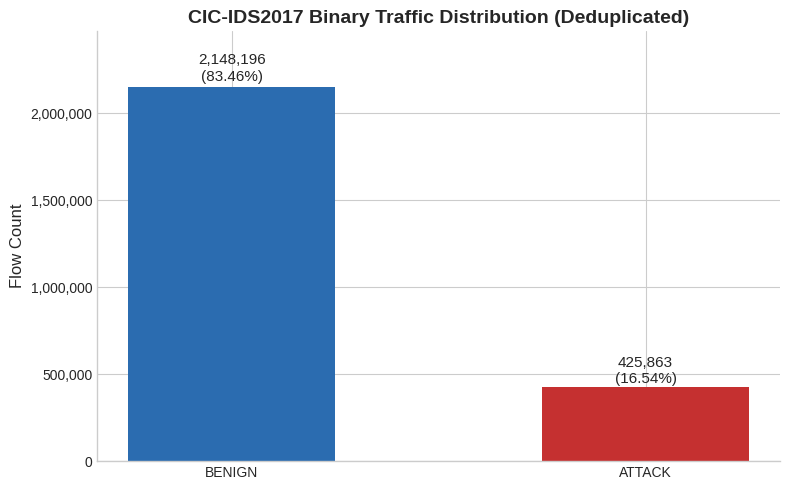

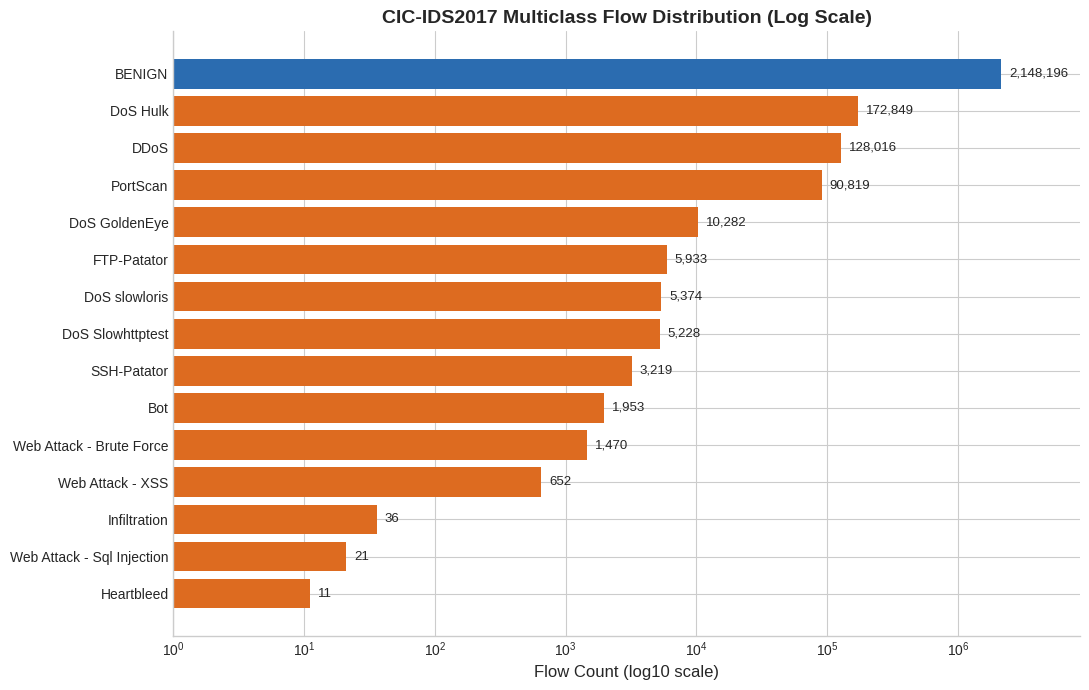

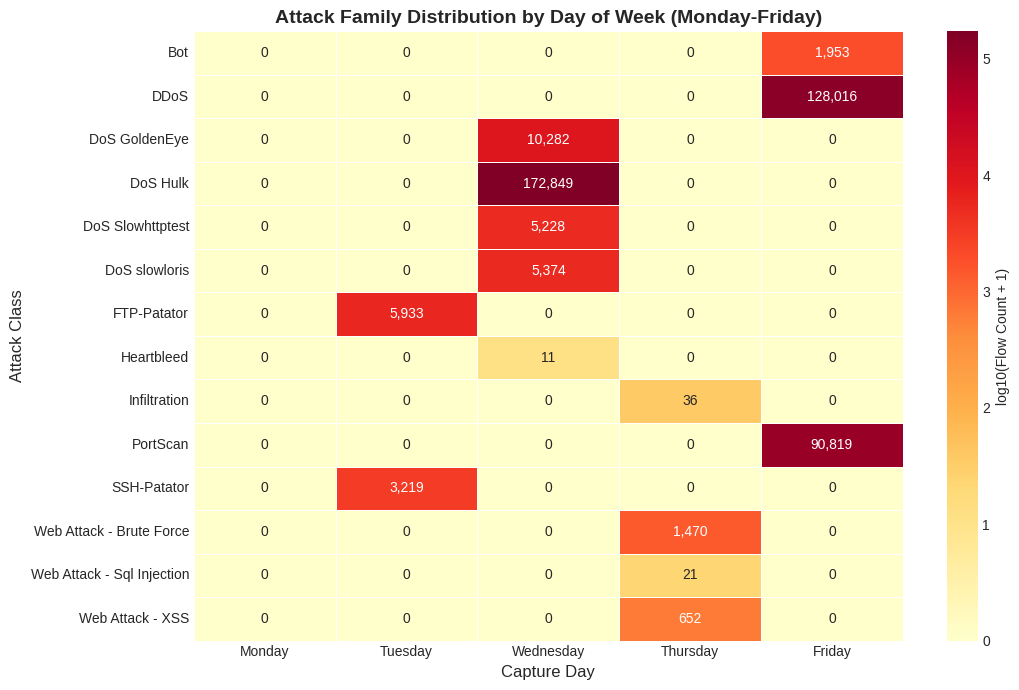

Saved EDA figures to: /content/drive/MyDrive/NetSentinel/figures

Day x Traffic Type summary (all flows):
Binary_Label  ATTACK  BENIGN
Day                         
Monday             0  502906
Tuesday         9152  412668
Wednesday     193744  417011
Thursday        2179  415041
Friday        220788  400570


19162

In [ ]:
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns

plt.style.use('seaborn-v0_8-whitegrid')

if 'df' not in globals():
  df = pd.read_parquet(PARQUET_PATH)

df['Binary_Label'] = np.where(df['Label'] == 'BENIGN', 'BENIGN', 'ATTACK')

# 1. Binary class distribution
bin_counts = df['Binary_Label'].value_counts().reindex(['BENIGN', 'ATTACK'])
fig, ax = plt.subplots(figsize=(8, 5))
colors = ['#2b6cb0', '#c53030']
bars = ax.bar(bin_counts.index, bin_counts.values, color=colors, width=0.5)
ax.set_title('CIC-IDS2017 Binary Traffic Distribution (Deduplicated)', fontsize=14, fontweight='bold')
ax.set_ylabel('Flow Count', fontsize=12)
ax.yaxis.set_major_formatter(mticker.StrMethodFormatter('{x:,.0f}'))
for bar, val in zip(bars, bin_counts.values):
  pct = 100.0 * val / len(df)
  ax.text(bar.get_x() + bar.get_width()/2, val * 1.01, f'{val:,}\n({pct:.2f}%)', ha='center', va='bottom', fontsize=11)
ax.set_ylim(0, bin_counts.max() * 1.15)
sns.despine()
plt.tight_layout()
fig.savefig(FIGURES_DIR / '01_binary_class_distribution.png', dpi=200)
plt.show()

# 2. Log-scale multiclass distribution across all 15 categories
cls_counts = df['Label'].value_counts().sort_values(ascending=True)
fig, ax = plt.subplots(figsize=(11, 7))
bar_colors = ['#2b6cb0' if lbl == 'BENIGN' else '#dd6b20' for lbl in cls_counts.index]
bars = ax.barh(cls_counts.index, cls_counts.values, color=bar_colors)
ax.set_xscale('log')
ax.set_title('CIC-IDS2017 Multiclass Flow Distribution (Log Scale)', fontsize=14, fontweight='bold')
ax.set_xlabel('Flow Count (log10 scale)', fontsize=12)
for bar, val in zip(bars, cls_counts.values):
  ax.text(val * 1.15, bar.get_y() + bar.get_height()/2, f'{val:,}', va='center', fontsize=9.5)
ax.set_xlim(1, cls_counts.max() * 4)
sns.despine()
plt.tight_layout()
fig.savefig(FIGURES_DIR / '02_multiclass_distribution_log.png', dpi=200)
plt.show()

# 3. Attack breakdown by day of the week (Monday-Friday)
days_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday']
attack_df = df[df['Label'] != 'BENIGN']
day_attack_ct = pd.crosstab(attack_df['Label'], attack_df['Day']).reindex(columns=days_order, fill_value=0)

fig, ax = plt.subplots(figsize=(11, 7))
sns.heatmap(
    np.log10(day_attack_ct + 1),
    annot=day_attack_ct,
    fmt=',d',
    cmap='YlOrRd',
    linewidths=0.5,
    cbar_kws={'label': 'log10(Flow Count + 1)'},
    ax=ax,
)
ax.set_title('Attack Family Distribution by Day of Week (Monday-Friday)', fontsize=14, fontweight='bold')
ax.set_xlabel('Capture Day', fontsize=12)
ax.set_ylabel('Attack Class', fontsize=12)
plt.tight_layout()
fig.savefig(FIGURES_DIR / '03_attack_by_day_heatmap.png', dpi=200)
plt.show()

print('Saved EDA figures to:', FIGURES_DIR)
print('\nDay x Traffic Type summary (all flows):')
print(pd.crosstab(df['Day'], df['Binary_Label']).reindex(days_order))
del attack_df
df.drop(columns=['Binary_Label'], inplace=True)
gc.collect()

In [ ]:
# Feature Selection: NaN audit, zero-variance removal, and >0.98 correlation pruning
meta_cols = ['Label', 'Source_File', 'Day']
feature_cols = [c for c in df.columns if c not in meta_cols]

# Audit NaNs (from +/-inf replacement or coercion)
nan_counts = df[feature_cols].isna().sum()
nan_cols = nan_counts[nan_counts > 0]
print(f'Columns with NaN values ({len(nan_cols)}):')
for col, cnt in nan_cols.items():
  print(f'  - {col}: {cnt:,} NaNs ({100*cnt/len(df):.4f}%)')

# 1. Identify zero-variance (constant) columns
stds = df[feature_cols].std(skipna=True)
zero_var_cols = stds[stds.fillna(0) == 0].index.tolist()
print(f'\nZero-variance columns dropped ({len(zero_var_cols)}):')
for c in zero_var_cols:
  print(f'  - {c} (unique non-null={df[c].nunique(dropna=True)})')

remaining_cols = [c for c in feature_cols if c not in zero_var_cols]

# 2. Inspect highly correlated features (>0.98 Pearson |r|)
# Compute on a 500k stratified/random sample or full data in float32->float64 safely
print(f'\nComputing correlation matrix across {len(remaining_cols)} non-constant features...')
corr_matrix = df[remaining_cols].corr(numeric_only=True).abs()
upper_tri = corr_matrix.where(np.triu(np.ones(corr_matrix.shape, dtype=bool), k=1))

high_corr_pairs = []
to_drop_corr = set()
for col in upper_tri.columns:
  matches = [m for m in upper_tri.index[upper_tri[col] > 0.98].tolist() if m not in to_drop_corr]
  for m in matches:
    r_val = float(upper_tri.loc[m, col])
    high_corr_pairs.append({'kept': m, 'dropped': col, 'abs_corr': round(r_val, 6)})
    to_drop_corr.add(col)

high_corr_dropped = [c for c in remaining_cols if c in to_drop_corr]
print(f'Highly correlated (>0.98) pairs found: {len(high_corr_pairs)}')
print(f'Redundant correlated columns dropped ({len(high_corr_dropped)}):')
for c in high_corr_dropped:
  pair = next(p for p in high_corr_pairs if p['dropped'] == c)
  print(f'  - {c} (|r|={pair["abs_corr"]:.4f} with {pair["kept"]})')

SELECTED_FEATURES = [c for c in remaining_cols if c not in to_drop_corr]
all_dropped = zero_var_cols + high_corr_dropped

# Drop redundant columns from working DataFrame to save RAM
df.drop(columns=all_dropped, inplace=True)
gc.collect()

feature_report = {
    'initial_feature_count': len(feature_cols),
    'zero_variance_dropped': zero_var_cols,
    'high_corr_threshold': 0.98,
    'high_corr_pairs': high_corr_pairs,
    'high_corr_dropped': high_corr_dropped,
    'selected_feature_count': len(SELECTED_FEATURES),
    'selected_features': SELECTED_FEATURES,
}
with open(ARTIFACTS_DIR / 'feature_selection_report.json', 'w') as f:
  json.dump(feature_report, f, indent=2)

print(f'\nFeatures reduced: {len(feature_cols)} -> {len(SELECTED_FEATURES)} (dropped {len(all_dropped)})')
print(f'Updated DataFrame shape: {df.shape} | Memory: {df.memory_usage(deep=True).sum() / 1e9:.2f} GB')

Columns with NaN values (2):
  - Flow Bytes/s: 1,624 NaNs (0.0631%)
  - Flow Packets/s: 1,624 NaNs (0.0631%)

Zero-variance columns dropped (8):
  - Bwd PSH Flags (unique non-null=1)
  - Bwd URG Flags (unique non-null=1)
  - Fwd Avg Bytes/Bulk (unique non-null=1)
  - Fwd Avg Packets/Bulk (unique non-null=1)
  - Fwd Avg Bulk Rate (unique non-null=1)
  - Bwd Avg Bytes/Bulk (unique non-null=1)
  - Bwd Avg Packets/Bulk (unique non-null=1)
  - Bwd Avg Bulk Rate (unique non-null=1)

Computing correlation matrix across 70 non-constant features...
Highly correlated (>0.98) pairs found: 20
Redundant correlated columns dropped (20):
  - Total Backward Packets (|r|=0.9991 with Total Fwd Packets)
  - Total Length of Bwd Packets (|r|=0.9970 with Total Fwd Packets)
  - Bwd Packet Length Std (|r|=0.9826 with Bwd Packet Length Max)
  - Fwd IAT Total (|r|=0.9985 with Flow Duration)
  - Fwd IAT Max (|r|=0.9981 with Flow IAT Max)
  - Fwd Packets/s (|r|=0.9801 with Flow Packets/s)
  - Packet Length Std (|

## Stage 3: Track A — Known-Attack Classification (Stratified Split)

In [ ]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder

# Load selected features if resuming from Parquet
if 'SELECTED_FEATURES' not in globals():
  with open(ARTIFACTS_DIR / 'feature_selection_report.json') as f:
    SELECTED_FEATURES = json.load(f)['selected_features']
if 'df' not in globals():
  df = pd.read_parquet(PARQUET_PATH, columns=SELECTED_FEATURES + ['Label', 'Source_File', 'Day'])

# Encode multiclass and binary targets
le_mc = LabelEncoder()
y_mc_all = le_mc.fit_transform(df['Label'].values)
y_bin_all = (df['Label'].values != 'BENIGN').astype(np.int32)

# Stratified 70% Train / 15% Val / 15% Test on multiclass label
# (Even Heartbleed with 11 rows yields >=1 sample in every split)
indices = np.arange(len(df))
idx_train, idx_temp, y_train_mc, y_temp_mc = train_test_split(
    indices, y_mc_all, test_size=0.30, stratify=y_mc_all, random_state=42
)
idx_val, idx_test, y_val_mc, y_test_mc = train_test_split(
    idx_temp, y_temp_mc, test_size=0.50, stratify=y_temp_mc, random_state=42
)

X_train_a = df.iloc[idx_train][SELECTED_FEATURES].to_numpy(dtype=np.float32)
X_val_a = df.iloc[idx_val][SELECTED_FEATURES].to_numpy(dtype=np.float32)
X_test_a = df.iloc[idx_test][SELECTED_FEATURES].to_numpy(dtype=np.float32)

y_train_bin = y_bin_all[idx_train]
y_val_bin = y_bin_all[idx_val]
y_test_bin = y_bin_all[idx_test]

# Verify every class is present in train, val, and test
split_check = pd.DataFrame({
    'Class': le_mc.classes_,
    'Train': np.bincount(y_train_mc, minlength=len(le_mc.classes_)),
    'Val': np.bincount(y_val_mc, minlength=len(le_mc.classes_)),
    'Test': np.bincount(y_test_mc, minlength=len(le_mc.classes_)),
})
assert (split_check[['Train', 'Val', 'Test']] >= 1).all().all(), 'Missing class in split!'

print(f'Track A shapes -> Train: {X_train_a.shape}, Val: {X_val_a.shape}, Test: {X_test_a.shape}')
print(f'Binary attack rate -> Train: {y_train_bin.mean():.4f}, Val: {y_val_bin.mean():.4f}, Test: {y_test_bin.mean():.4f}')
print('\nStratified Multiclass Split Counts:')
print(split_check.to_string(index=False))

Track A shapes -> Train: (1801841, 50), Val: (386109, 50), Test: (386109, 50)
Binary attack rate -> Train: 0.1654, Val: 0.1654, Test: 0.1654

Stratified Multiclass Split Counts:
                     Class   Train    Val   Test
                    BENIGN 1503737 322229 322230
                       Bot    1367    293    293
                      DDoS   89611  19203  19202
             DoS GoldenEye    7197   1542   1543
                  DoS Hulk  120994  25927  25928
          DoS Slowhttptest    3660    784    784
             DoS slowloris    3762    806    806
               FTP-Patator    4153    890    890
                Heartbleed       8      1      2
              Infiltration      25      6      5
                  PortScan   63573  13623  13623
               SSH-Patator    2253    483    483
  Web Attack - Brute Force    1029    221    220
Web Attack - Sql Injection      15      3      3
          Web Attack - XSS     457     98     97


Track A Binary scale_pos_weight: 5.0443

Training RandomForest_Binary...

Training XGBoost_Binary...

=== Track A: Binary Detection Results ===
              Model Split  Precision   Recall       F1  ROC_AUC   PR_AUC
RandomForest_Binary   Val   0.995193 0.998278 0.996733 0.999943 0.999749
RandomForest_Binary  Test   0.994666 0.998309 0.996484 0.999936 0.999757
     XGBoost_Binary   Val   0.995261 0.999499 0.997376 0.999978 0.999900
     XGBoost_Binary  Test   0.994997 0.999405 0.997196 0.999973 0.999879


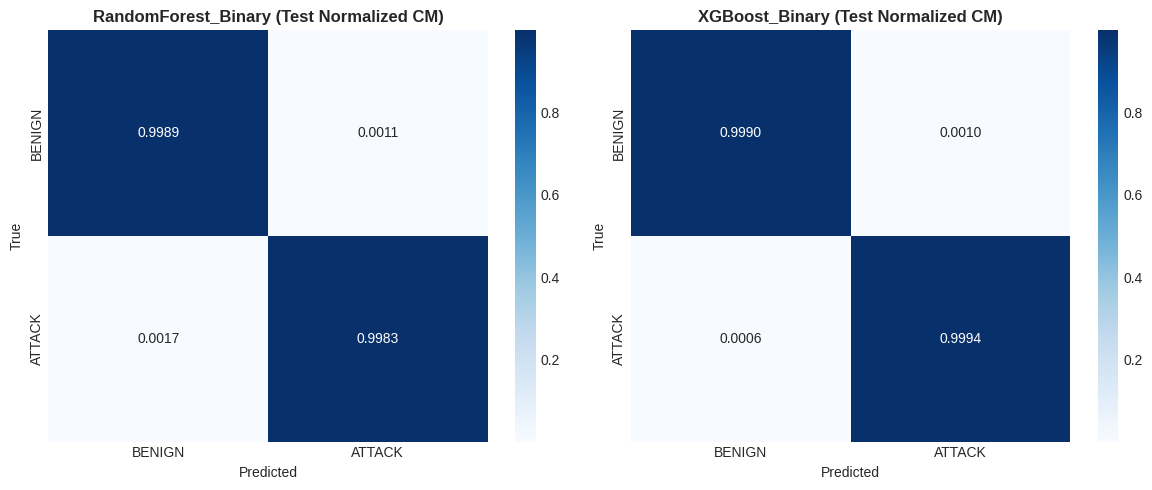

17680

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score, recall_score, f1_score,
    roc_auc_score, average_precision_score, confusion_matrix, classification_report
)

pos_weight_bin = float((y_train_bin == 0).sum() / (y_train_bin == 1).sum())
print(f'Track A Binary scale_pos_weight: {pos_weight_bin:.4f}')

rf_bin_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', RandomForestClassifier(
        n_estimators=80,
        max_depth=20,
        min_samples_leaf=2,
        max_samples=0.25,
        class_weight='balanced_subsample',
        n_jobs=-1,
        random_state=42,
    )),
])

xgb_bin_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', xgb.XGBClassifier(
        tree_method='hist',
        device='cuda',
        n_estimators=250,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        scale_pos_weight=pos_weight_bin,
        eval_metric='logloss',
        random_state=42,
    )),
])

binary_models = {'RandomForest_Binary': rf_bin_pipe, 'XGBoost_Binary': xgb_bin_pipe}
binary_results = []
binary_cms = {}

for name, pipe in binary_models.items():
  print(f'\nTraining {name}...')
  pipe.fit(X_train_a, y_train_bin)
  for split_name, X_sp, y_sp in [('Val', X_val_a, y_val_bin), ('Test', X_test_a, y_test_bin)]:
    y_prob = pipe.predict_proba(X_sp)[:, 1]
    y_pred = (y_prob >= 0.5).astype(np.int32)
    row = {
        'Model': name,
        'Split': split_name,
        'Precision': precision_score(y_sp, y_pred),
        'Recall': recall_score(y_sp, y_pred),
        'F1': f1_score(y_sp, y_pred),
        'ROC_AUC': roc_auc_score(y_sp, y_prob),
        'PR_AUC': average_precision_score(y_sp, y_prob),
    }
    binary_results.append(row)
    if split_name == 'Test':
      binary_cms[name] = confusion_matrix(y_sp, y_pred, normalize='true')

binary_df = pd.DataFrame(binary_results)
print('\n=== Track A: Binary Detection Results ===')
print(binary_df.to_string(index=False))

# Plot normalized confusion matrices on Test set
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (name, cm) in zip(axes, binary_cms.items()):
  sns.heatmap(cm, annot=True, fmt='.4f', cmap='Blues', xticklabels=['BENIGN', 'ATTACK'], yticklabels=['BENIGN', 'ATTACK'], ax=ax)
  ax.set_title(f'{name} (Test Normalized CM)', fontsize=12, fontweight='bold')
  ax.set_xlabel('Predicted')
  ax.set_ylabel('True')
plt.tight_layout()
fig.savefig(FIGURES_DIR / '04_track_a_binary_confusion.png', dpi=200)
plt.show()

binary_df.to_csv(ARTIFACTS_DIR / 'track_a_binary_metrics.csv', index=False)
del rf_bin_pipe, xgb_bin_pipe, binary_models
gc.collect()

Training RandomForest_Multiclass...
Training XGBoost_Multiclass (GPU)...

--- RandomForest_Multiclass Test Classification Report ---
                            precision    recall  f1-score   support

                    BENIGN     0.9997    0.9961    0.9979    322230
                       Bot     0.2439    0.9556    0.3886       293
                      DDoS     0.9999    0.9989    0.9994     19202
             DoS GoldenEye     0.9910    0.9955    0.9932      1543
                  DoS Hulk     0.9921    0.9993    0.9957     25928
          DoS Slowhttptest     0.9885    0.9885    0.9885       784
             DoS slowloris     1.0000    0.9839    0.9919       806
               FTP-Patator     1.0000    0.9966    0.9983       890
                Heartbleed     0.0000    0.0000    0.0000         2
              Infiltration     0.0000    0.0000    0.0000         5
                  PortScan     0.9887    0.9990    0.9938     13623
               SSH-Patator     1.0000    0.9896   

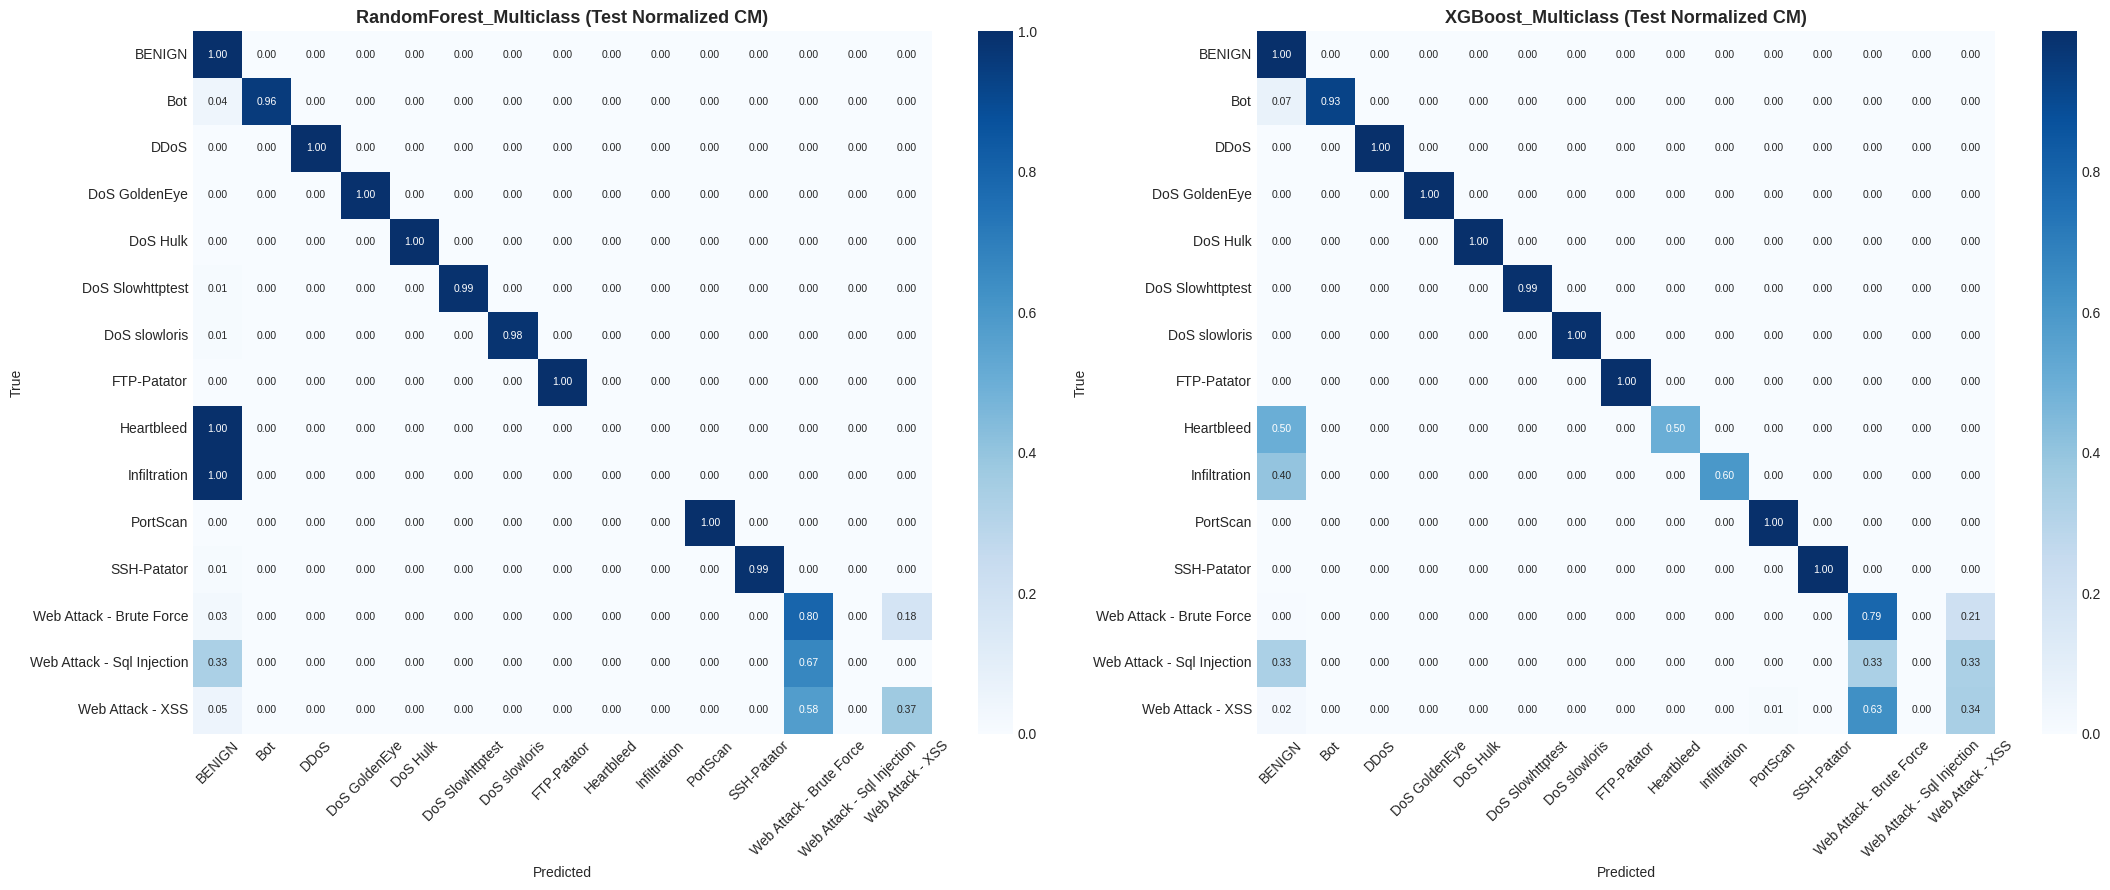

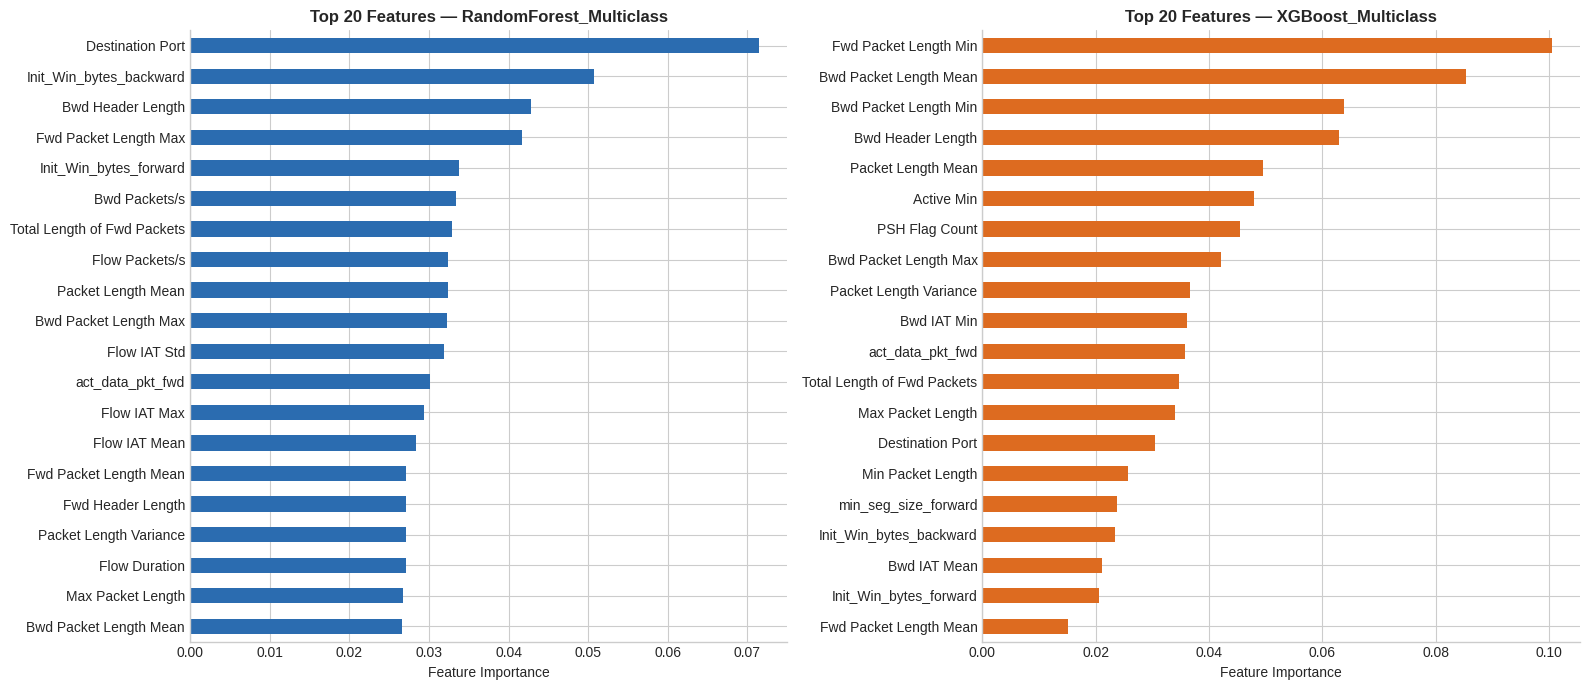

46726

In [ ]:
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.preprocessing import label_binarize
from sklearn.metrics import accuracy_score

# Compute capped balanced sample weights for Multiclass XGBoost (handles ultra-rare classes stably)
raw_sw = compute_sample_weight(class_weight='balanced', y=y_train_mc)
xgb_sw_mc = np.clip(raw_sw, 1.0, 1000.0).astype(np.float32)

rf_mc_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', RandomForestClassifier(
        n_estimators=60,
        max_depth=18,
        min_samples_leaf=2,
        max_samples=0.15,
        class_weight='balanced_subsample',
        n_jobs=-1,
        random_state=42,
    )),
])

xgb_mc_pipe = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', xgb.XGBClassifier(
        tree_method='hist',
        device='cuda',
        n_estimators=250,
        max_depth=8,
        learning_rate=0.1,
        subsample=0.8,
        colsample_bytree=0.8,
        objective='multi:softprob',
        num_class=len(le_mc.classes_),
        eval_metric='mlogloss',
        random_state=42,
    )),
])

print('Training RandomForest_Multiclass...')
rf_mc_pipe.fit(X_train_a, y_train_mc)

print('Training XGBoost_Multiclass (GPU)...')
xgb_mc_pipe.fit(X_train_a, y_train_mc, clf__sample_weight=xgb_sw_mc)

mc_models = {'RandomForest_Multiclass': rf_mc_pipe, 'XGBoost_Multiclass': xgb_mc_pipe}
mc_results = []
mc_cms = {}
class_ids = np.arange(len(le_mc.classes_))

for name, pipe in mc_models.items():
  for split_name, X_sp, y_sp in [('Val', X_val_a, y_val_mc), ('Test', X_test_a, y_test_mc)]:
    y_prob = pipe.predict_proba(X_sp)
    y_pred = np.argmax(y_prob, axis=1)
    y_bin_true = label_binarize(y_sp, classes=class_ids)
    mc_results.append({
        'Model': name,
        'Split': split_name,
        'Accuracy': accuracy_score(y_sp, y_pred),
        'Precision_Weighted': precision_score(y_sp, y_pred, average='weighted', zero_division=0),
        'Recall_Weighted': recall_score(y_sp, y_pred, average='weighted', zero_division=0),
        'F1_Weighted': f1_score(y_sp, y_pred, average='weighted', zero_division=0),
        'Precision_Macro': precision_score(y_sp, y_pred, average='macro', zero_division=0),
        'Recall_Macro': recall_score(y_sp, y_pred, average='macro', zero_division=0),
        'F1_Macro': f1_score(y_sp, y_pred, average='macro', zero_division=0),
        'ROC_AUC_OvR_Macro': roc_auc_score(y_bin_true, y_prob, multi_class='ovr', average='macro'),
        'PR_AUC_Macro': average_precision_score(y_bin_true, y_prob, average='macro'),
        'PR_AUC_Weighted': average_precision_score(y_bin_true, y_prob, average='weighted'),
    })
    if split_name == 'Test':
      mc_cms[name] = confusion_matrix(y_sp, y_pred, normalize='true')
      print(f'\n--- {name} Test Classification Report ---')
      print(classification_report(y_sp, y_pred, target_names=le_mc.classes_, digits=4, zero_division=0))

mc_df = pd.DataFrame(mc_results)
print('\n=== Track A: Multiclass Summary ===')
print(mc_df.to_string(index=False))
mc_df.to_csv(ARTIFACTS_DIR / 'track_a_multiclass_metrics.csv', index=False)

# Normalized Multiclass Confusion Matrices
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
for ax, (name, cm) in zip(axes, mc_cms.items()):
  sns.heatmap(
      cm, annot=True, fmt='.2f', cmap='Blues',
      xticklabels=le_mc.classes_, yticklabels=le_mc.classes_, ax=ax,
      annot_kws={'size': 7.5}
  )
  ax.set_title(f'{name} (Test Normalized CM)', fontsize=13, fontweight='bold')
  ax.set_xlabel('Predicted')
  ax.set_ylabel('True')
  ax.tick_params(axis='x', rotation=45)
plt.tight_layout()
fig.savefig(FIGURES_DIR / '05_track_a_multiclass_confusion.png', dpi=200)
plt.show()

# Top 20 Feature Importances (RF & XGBoost)
fig, axes = plt.subplots(1, 2, figsize=(16, 7))
for ax, (name, pipe) in zip(axes, mc_models.items()):
  imps = pd.Series(pipe.named_steps['clf'].feature_importances_, index=SELECTED_FEATURES).sort_values(ascending=True).tail(20)
  imps.plot(kind='barh', ax=ax, color='#2b6cb0' if 'Random' in name else '#dd6b20')
  ax.set_title(f'Top 20 Features — {name}', fontsize=12, fontweight='bold')
  ax.set_xlabel('Feature Importance')
  sns.despine(ax=ax)
plt.tight_layout()
fig.savefig(FIGURES_DIR / '06_track_a_top20_features.png', dpi=200)
plt.show()

# Save Track A best multiclass model and free Track A arrays
joblib.dump({'pipeline': xgb_mc_pipe, 'label_encoder': le_mc, 'features': SELECTED_FEATURES}, MODELS_DIR / 'track_a_xgb_multiclass.joblib')
del rf_mc_pipe, xgb_mc_pipe, mc_models, X_train_a, X_val_a, X_test_a, xgb_sw_mc, raw_sw
gc.collect()

## Stage 4: Track B — Unseen-Attack Generalization (Temporal Friday Holdout)

In [ ]:
# Temporal split: Monday-Thursday (Train/Val) vs. Friday (Held-out Unseen Test)
mon_thu_df = df[df['Day'] != 'Friday'].reset_index(drop=True)
fri_df = df[df['Day'] == 'Friday'].reset_index(drop=True)

# Stratified 80/20 split within Monday-Thursday
mt_idx = np.arange(len(mon_thu_df))
mt_train_idx, mt_val_idx = train_test_split(
    mt_idx, test_size=0.20, stratify=mon_thu_df['Label'].values, random_state=42
)

X_train_b = mon_thu_df.iloc[mt_train_idx][SELECTED_FEATURES].to_numpy(dtype=np.float32)
y_train_b = (mon_thu_df.iloc[mt_train_idx]['Label'].values != 'BENIGN').astype(np.int32)
y_train_b_lbl = mon_thu_df.iloc[mt_train_idx]['Label'].values

X_val_b = mon_thu_df.iloc[mt_val_idx][SELECTED_FEATURES].to_numpy(dtype=np.float32)
y_val_b = (mon_thu_df.iloc[mt_val_idx]['Label'].values != 'BENIGN').astype(np.int32)
y_val_b_lbl = mon_thu_df.iloc[mt_val_idx]['Label'].values

X_test_fri = fri_df[SELECTED_FEATURES].to_numpy(dtype=np.float32)
y_test_fri = (fri_df['Label'].values != 'BENIGN').astype(np.int32)
y_test_fri_lbl = fri_df['Label'].values

print(f'Mon-Thu Train: {X_train_b.shape} | Attacks: {y_train_b.sum():,} ({y_train_b.mean():.4f})')
print(f'Mon-Thu Val:   {X_val_b.shape} | Attacks: {y_val_b.sum():,} ({y_val_b.mean():.4f})')
print(f'Friday Test:   {X_test_fri.shape} | Attacks: {y_test_fri.sum():,} ({y_test_fri.mean():.4f})')
print('\nFriday Test class breakdown (completely unseen attack campaigns):')
print(pd.Series(y_test_fri_lbl).value_counts())

# Baseline Supervised Models trained ONLY on Mon-Thu
pos_weight_b = float((y_train_b == 0).sum() / (y_train_b == 1).sum())

rf_track_b = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', RandomForestClassifier(
        n_estimators=60, max_depth=18, min_samples_leaf=2,
        max_samples=0.15, class_weight='balanced_subsample',
        n_jobs=-1, random_state=42
    )),
])

xgb_track_b = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('clf', xgb.XGBClassifier(
        tree_method='hist', device='cuda', n_estimators=250,
        max_depth=8, learning_rate=0.1, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=pos_weight_b,
        eval_metric='logloss', random_state=42
    )),
])

print('\nTraining Track B Baseline Supervised Models on Mon-Thu...')
rf_track_b.fit(X_train_b, y_train_b)
xgb_track_b.fit(X_train_b, y_train_b)

def eval_binary(name, split_name, y_true, y_prob, thr=0.5):
  y_pred = (y_prob >= thr).astype(np.int32)
  return {
      'Model': name, 'Split': split_name,
      'Precision': precision_score(y_true, y_pred, zero_division=0),
      'Recall': recall_score(y_true, y_pred, zero_division=0),
      'F1': f1_score(y_true, y_pred, zero_division=0),
      'FPR': float(((y_pred == 1) & (y_true == 0)).sum() / max((y_true == 0).sum(), 1)),
      'ROC_AUC': roc_auc_score(y_true, y_prob),
      'PR_AUC': average_precision_score(y_true, y_prob),
  }

# Cache probabilities for comparison
val_prob_rf = rf_track_b.predict_proba(X_val_b)[:, 1]
fri_prob_rf = rf_track_b.predict_proba(X_test_fri)[:, 1]
val_prob_xgb = xgb_track_b.predict_proba(X_val_b)[:, 1]
fri_prob_xgb = xgb_track_b.predict_proba(X_test_fri)[:, 1]

baseline_b_rows = [
    eval_binary('RF_Supervised_Only', 'MonThu_Val', y_val_b, val_prob_rf),
    eval_binary('RF_Supervised_Only', 'Friday_Test', y_test_fri, fri_prob_rf),
    eval_binary('XGB_Supervised_Only', 'MonThu_Val', y_val_b, val_prob_xgb),
    eval_binary('XGB_Supervised_Only', 'Friday_Test', y_test_fri, fri_prob_xgb),
]
print('\n=== Track B Baseline Supervised Performance (Mon-Thu Val vs. Unseen Friday Test) ===')
print(pd.DataFrame(baseline_b_rows).to_string(index=False))

# Per-attack-class recall on Friday Test
for name, f_prob in [('RF_Supervised_Only', fri_prob_rf), ('XGB_Supervised_Only', fri_prob_xgb)]:
  f_pred = (f_prob >= 0.5).astype(np.int32)
  print(f'\n{name} — Per-Class Recall / Detection Rate on Friday:')
  for cls_name in ['BENIGN', 'DDoS', 'PortScan', 'Bot']:
    mask = (y_test_fri_lbl == cls_name)
    det_rate = (f_pred[mask] == 1).mean()
    print(f'  - {cls_name:10s} (n={mask.sum():>7,}): flagged as ATTACK = {det_rate:.4f}')

del mon_thu_df, fri_df
gc.collect()

Mon-Thu Train: (1562160, 50) | Attacks: 164,060 (0.1050)
Mon-Thu Val:   (390541, 50) | Attacks: 41,015 (0.1050)
Friday Test:   (621358, 50) | Attacks: 220,788 (0.3553)

Friday Test class breakdown (completely unseen attack campaigns):
BENIGN      400570
DDoS        128016
PortScan     90819
Bot           1953
Name: count, dtype: int64

Training Track B Baseline Supervised Models on Mon-Thu...

=== Track B Baseline Supervised Performance (Mon-Thu Val vs. Unseen Friday Test) ===
              Model       Split  Precision   Recall       F1      FPR  ROC_AUC   PR_AUC
 RF_Supervised_Only  MonThu_Val   0.995867 0.998757 0.997310 0.000486 0.999995 0.999958
 RF_Supervised_Only Friday_Test   0.990552 0.080729 0.149291 0.000424 0.845313 0.803910
XGB_Supervised_Only  MonThu_Val   0.998077 0.999829 0.998953 0.000226 0.999999 0.999991
XGB_Supervised_Only Friday_Test   0.870036 0.002183 0.004355 0.000180 0.706661 0.726784

RF_Supervised_Only — Per-Class Recall / Detection Rate on Friday:
  - BENIGN 

143

In [ ]:
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.preprocessing import StandardScaler, FunctionTransformer
from sklearn.ensemble import IsolationForest

# Signed log1p transform stabilizes heavy-tailed flow byte/packet features
def signed_log1p(X):
  return np.sign(X) * np.log1p(np.abs(X))

# 1. Fit unsupervised preprocessor EXCLUSIVELY on Mon-Thu BENIGN training flows
benign_mask_train = (y_train_b == 0)
X_train_benign = X_train_b[benign_mask_train]
print(f'Fitting unsupervised preprocessor & detectors exclusively on {len(X_train_benign):,} Mon-Thu BENIGN flows...')

unsup_prep = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('log1p', FunctionTransformer(signed_log1p, validate=False)),
    ('scaler', StandardScaler()),
])
X_benign_scaled = unsup_prep.fit_transform(X_train_benign).astype(np.float32)
X_benign_scaled = np.clip(X_benign_scaled, -20.0, 20.0)

X_val_scaled = np.clip(unsup_prep.transform(X_val_b).astype(np.float32), -20.0, 20.0)
X_fri_scaled = np.clip(unsup_prep.transform(X_test_fri).astype(np.float32), -20.0, 20.0)

# 2A. Isolation Forest trained exclusively on 300k Mon-Thu BENIGN flows
rng = np.random.RandomState(42)
if_sub_idx = rng.choice(len(X_benign_scaled), size=min(300_000, len(X_benign_scaled)), replace=False)
iso_forest = IsolationForest(
    n_estimators=150, max_samples=4096, contamination='auto', n_jobs=-1, random_state=42
)
print('Training Isolation Forest on BENIGN flows...')
iso_forest.fit(X_benign_scaled[if_sub_idx])

# Higher score = more anomalous
val_anom_if = -iso_forest.decision_function(X_val_scaled)
fri_anom_if = -iso_forest.decision_function(X_fri_scaled)

# 2B. PyTorch Deep Autoencoder trained on GPU exclusively on all Mon-Thu BENIGN flows
class FlowAutoencoder(nn.Module):
  def __init__(self, in_dim: int):
    super().__init__()
    self.encoder = nn.Sequential(
        nn.Linear(in_dim, 32), nn.BatchNorm1d(32), nn.LeakyReLU(0.1),
        nn.Linear(32, 16), nn.BatchNorm1d(16), nn.LeakyReLU(0.1),
        nn.Linear(16, 8), nn.LeakyReLU(0.1),
    )
    self.decoder = nn.Sequential(
        nn.Linear(8, 16), nn.BatchNorm1d(16), nn.LeakyReLU(0.1),
        nn.Linear(16, 32), nn.BatchNorm1d(32), nn.LeakyReLU(0.1),
        nn.Linear(32, in_dim),
    )
  def forward(self, x):
    return self.decoder(self.encoder(x))

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
torch.manual_seed(42)
ae_model = FlowAutoencoder(X_benign_scaled.shape[1]).to(device)
optimizer = torch.optim.AdamW(ae_model.parameters(), lr=1e-3, weight_decay=1e-5)
criterion = nn.MSELoss()

train_loader = DataLoader(
    TensorDataset(torch.from_numpy(X_benign_scaled)),
    batch_size=8192, shuffle=True, drop_last=len(X_benign_scaled) >= 8192
)

print(f'Training PyTorch Deep Autoencoder on {device} for 12 epochs...')
ae_model.train()
for epoch in range(1, 13):
  epoch_loss = 0.0
  n_seen = 0
  for (batch_x,) in train_loader:
    batch_x = batch_x.to(device, non_blocking=True)
    optimizer.zero_grad()
    recon = ae_model(batch_x)
    loss = criterion(recon, batch_x)
    loss.backward()
    optimizer.step()
    epoch_loss += loss.item() * len(batch_x)
    n_seen += len(batch_x)
  if epoch in [1, 4, 8, 12]:
    print(f'  Epoch {epoch:2d}/12 | BENIGN MSE Loss: {epoch_loss / max(n_seen, 1):.6f}')

@torch.no_grad()
def score_autoencoder(model, X_arr, batch_size=16384):
  model.eval()
  scores = np.empty(len(X_arr), dtype=np.float32)
  for start in range(0, len(X_arr), batch_size):
    end = min(start + batch_size, len(X_arr))
    xb = torch.from_numpy(X_arr[start:end]).to(device)
    recon = model(xb)
    mse = torch.mean((recon - xb) ** 2, dim=1)
    scores[start:end] = mse.cpu().numpy()
  return scores

val_anom_ae = score_autoencoder(ae_model, X_val_scaled)
fri_anom_ae = score_autoencoder(ae_model, X_fri_scaled)

del X_train_benign, X_benign_scaled, train_loader
gc.collect()
print('Completed unsupervised anomaly scoring on Mon-Thu Val and Friday Test.')

Fitting unsupervised preprocessor & detectors exclusively on 1,398,100 Mon-Thu BENIGN flows...
Training Isolation Forest on BENIGN flows...
Training PyTorch Deep Autoencoder on cuda for 12 epochs...
  Epoch  1/12 | BENIGN MSE Loss: 0.396611
  Epoch  4/12 | BENIGN MSE Loss: 0.085835
  Epoch  8/12 | BENIGN MSE Loss: 0.053137
  Epoch 12/12 | BENIGN MSE Loss: 0.042548
Completed unsupervised anomaly scoring on Mon-Thu Val and Friday Test.


=== Mon-Thu Validation Threshold Tuning: Isolation Forest ===
 Percentile  Threshold  Val_Precision  Val_Recall   Val_F1  Val_BENIGN_FPR
       90.0  -0.002005       0.493508    0.830379 0.619084        0.100004
       93.0   0.015495       0.575520    0.808802 0.672505        0.070001
       95.0   0.033699       0.645576    0.776155 0.704869        0.050002
       96.0   0.044415       0.692751    0.768621 0.728716        0.040003
       97.0   0.059786       0.688981    0.566354 0.621678        0.030001
       98.0   0.075035       0.539035    0.199317 0.291024        0.020001
       99.0   0.093497       0.335234    0.043009 0.076237        0.010008
-> Selected tau_if (Mon-Thu Val): 0.044415

=== Mon-Thu Validation Threshold Tuning: Deep Autoencoder ===
 Percentile  Threshold  Val_Precision  Val_Recall   Val_F1  Val_BENIGN_FPR
       90.0   0.085392       0.521284    0.927978 0.667567        0.100001
       93.0   0.108285       0.601936    0.902060 0.722053        0.070001
       

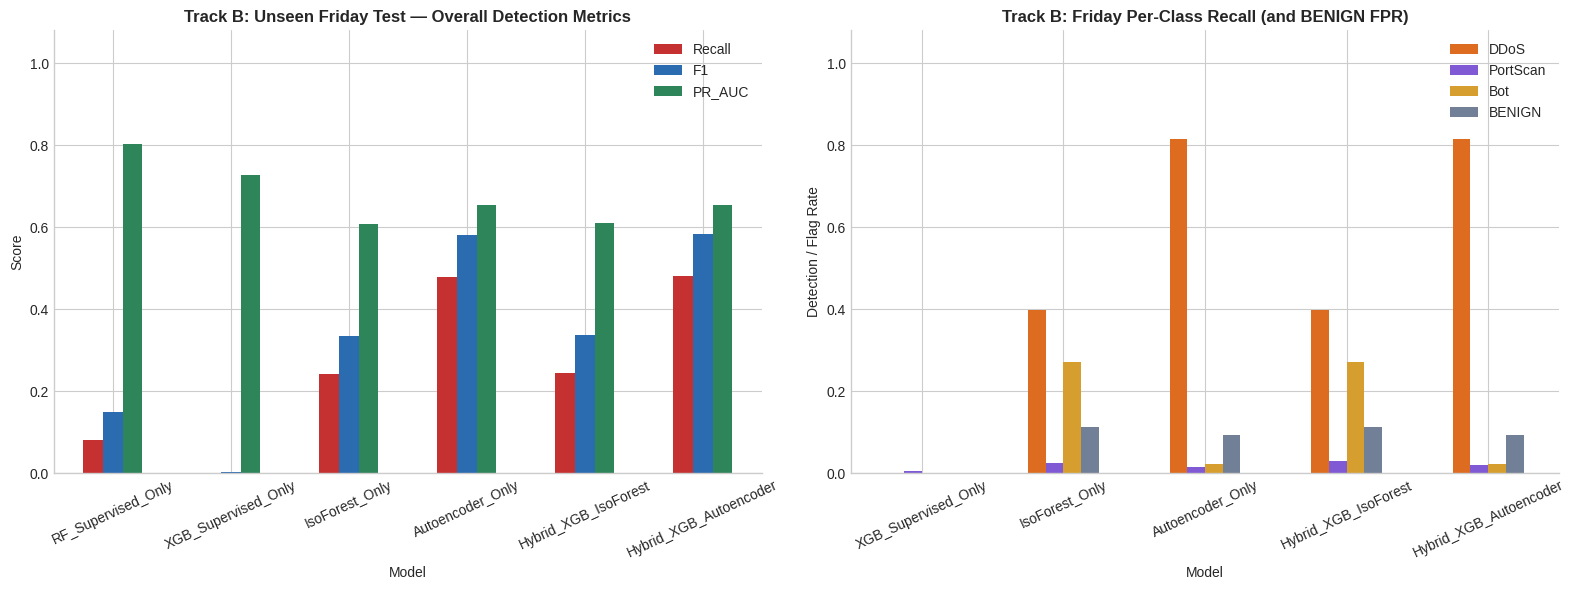

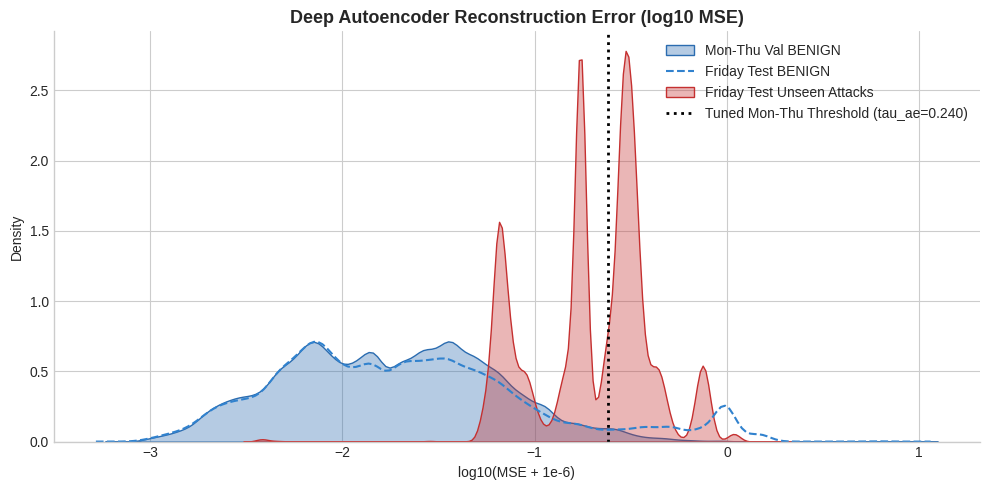

In [ ]:
# Tune thresholds strictly on Mon-Thu Validation (ZERO peeking at Friday Test)
def tune_anomaly_threshold_on_val(val_scores, y_val, max_fpr=0.05):
  benign_scores = val_scores[y_val == 0]
  candidates = []
  for pct in [90.0, 93.0, 95.0, 96.0, 97.0, 98.0, 99.0]:
    thr = float(np.percentile(benign_scores, pct))
    y_pred = (val_scores >= thr).astype(np.int32)
    fpr = float(((y_pred == 1) & (y_val == 0)).sum() / (y_val == 0).sum())
    candidates.append({
        'Percentile': pct,
        'Threshold': thr,
        'Val_Precision': precision_score(y_val, y_pred, zero_division=0),
        'Val_Recall': recall_score(y_val, y_pred, zero_division=0),
        'Val_F1': f1_score(y_val, y_pred, zero_division=0),
        'Val_BENIGN_FPR': fpr,
    })
  cand_df = pd.DataFrame(candidates)
  feasible = cand_df[cand_df['Val_BENIGN_FPR'] <= max_fpr]
  best_row = feasible.sort_values('Val_F1', ascending=False).iloc[0] if len(feasible) else cand_df.sort_values('Val_F1', ascending=False).iloc[0]
  return float(best_row['Threshold']), cand_df

tau_if, if_tune_df = tune_anomaly_threshold_on_val(val_anom_if, y_val_b, max_fpr=0.05)
tau_ae, ae_tune_df = tune_anomaly_threshold_on_val(val_anom_ae, y_val_b, max_fpr=0.05)
tau_sup = 0.5

print('=== Mon-Thu Validation Threshold Tuning: Isolation Forest ===')
print(if_tune_df.to_string(index=False))
print(f'-> Selected tau_if (Mon-Thu Val): {tau_if:.6f}\n')

print('=== Mon-Thu Validation Threshold Tuning: Deep Autoencoder ===')
print(ae_tune_df.to_string(index=False))
print(f'-> Selected tau_ae (Mon-Thu Val): {tau_ae:.6f}\n')

# Convert raw anomaly scores to monotonic [0, 1] probabilities centered at threshold (score == tau -> p == 0.5)
def anom_to_prob(scores, tau, scale):
  z = np.clip((scores - tau) / max(scale, 1e-6), -30.0, 30.0)
  return (1.0 / (1.0 + np.exp(-z))).astype(np.float32)

if_scale = float(np.std(val_anom_if[y_val_b == 0]))
ae_scale = float(np.std(val_anom_ae[y_val_b == 0]))

val_p_if = anom_to_prob(val_anom_if, tau_if, if_scale)
fri_p_if = anom_to_prob(fri_anom_if, tau_if, if_scale)

val_p_ae = anom_to_prob(val_anom_ae, tau_ae, ae_scale)
fri_p_ae = anom_to_prob(fri_anom_ae, tau_ae, ae_scale)

# Hybrid risk score: max(p_supervised, p_anomaly) -> alert if either >= 0.5
val_p_hyb_if = np.maximum(val_prob_xgb, val_p_if)
fri_p_hyb_if = np.maximum(fri_prob_xgb, fri_p_if)

val_p_hyb_ae = np.maximum(val_prob_xgb, val_p_ae)
fri_p_hyb_ae = np.maximum(fri_prob_xgb, fri_p_ae)

track_b_rows = [
    eval_binary('RF_Supervised_Only', 'MonThu_Val', y_val_b, val_prob_rf),
    eval_binary('RF_Supervised_Only', 'Friday_Test', y_test_fri, fri_prob_rf),
    eval_binary('XGB_Supervised_Only', 'MonThu_Val', y_val_b, val_prob_xgb),
    eval_binary('XGB_Supervised_Only', 'Friday_Test', y_test_fri, fri_prob_xgb),
    eval_binary('IsoForest_Only', 'MonThu_Val', y_val_b, val_p_if),
    eval_binary('IsoForest_Only', 'Friday_Test', y_test_fri, fri_p_if),
    eval_binary('Autoencoder_Only', 'MonThu_Val', y_val_b, val_p_ae),
    eval_binary('Autoencoder_Only', 'Friday_Test', y_test_fri, fri_p_ae),
    eval_binary('Hybrid_XGB_IsoForest', 'MonThu_Val', y_val_b, val_p_hyb_if),
    eval_binary('Hybrid_XGB_IsoForest', 'Friday_Test', y_test_fri, fri_p_hyb_if),
    eval_binary('Hybrid_XGB_Autoencoder', 'MonThu_Val', y_val_b, val_p_hyb_ae),
    eval_binary('Hybrid_XGB_Autoencoder', 'Friday_Test', y_test_fri, fri_p_hyb_ae),
]
track_b_df = pd.DataFrame(track_b_rows)
print('=== Track B Full Comparison (Mon-Thu Val vs. Unseen Friday Test) ===')
print(track_b_df.to_string(index=False))
track_b_df.to_csv(ARTIFACTS_DIR / 'track_b_metrics.csv', index=False)

# Per-class Friday detection rates
fri_models_map = {
    'XGB_Supervised_Only': fri_prob_xgb,
    'IsoForest_Only': fri_p_if,
    'Autoencoder_Only': fri_p_ae,
    'Hybrid_XGB_IsoForest': fri_p_hyb_if,
    'Hybrid_XGB_Autoencoder': fri_p_hyb_ae,
}
per_cls_rows = []
for mname, probs in fri_models_map.items():
  preds = (probs >= 0.5).astype(np.int32)
  row = {'Model': mname}
  for cls_name in ['BENIGN', 'DDoS', 'PortScan', 'Bot']:
    mask = (y_test_fri_lbl == cls_name)
    row[cls_name] = float((preds[mask] == 1).mean())
  per_cls_rows.append(row)
per_cls_df = pd.DataFrame(per_cls_rows)
print('\n=== Friday Test Per-Class Flagged-as-Attack Rate (BENIGN=FPR, Attacks=Recall) ===')
print(per_cls_df.to_string(index=False))
per_cls_df.to_csv(ARTIFACTS_DIR / 'track_b_friday_per_class.csv', index=False)

# Visualization 1: Friday Test Comparison
fri_only_df = track_b_df[track_b_df['Split'] == 'Friday_Test'].set_index('Model')
fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fri_only_df[['Recall', 'F1', 'PR_AUC']].plot(kind='bar', ax=axes[0], color=['#c53030', '#2b6cb0', '#2f855a'])
axes[0].set_title('Track B: Unseen Friday Test — Overall Detection Metrics', fontsize=12, fontweight='bold')
axes[0].set_ylabel('Score')
axes[0].set_ylim(0, 1.08)
axes[0].tick_params(axis='x', rotation=25)
sns.despine(ax=axes[0])

per_cls_df.set_index('Model')[['DDoS', 'PortScan', 'Bot', 'BENIGN']].plot(kind='bar', ax=axes[1], color=['#dd6b20', '#805ad5', '#d69e2e', '#718096'])
axes[1].set_title('Track B: Friday Per-Class Recall (and BENIGN FPR)', fontsize=12, fontweight='bold')
axes[1].set_ylabel('Detection / Flag Rate')
axes[1].set_ylim(0, 1.08)
axes[1].tick_params(axis='x', rotation=25)
sns.despine(ax=axes[1])
plt.tight_layout()
fig.savefig(FIGURES_DIR / '07_track_b_friday_comparison.png', dpi=200)
plt.show()

# Visualization 2: Autoencoder Reconstruction Error Distribution (Val BENIGN vs Friday Attacks)
fig, ax = plt.subplots(figsize=(10, 5))
val_ben_ae = np.log10(val_anom_ae[y_val_b == 0] + 1e-6)
fri_atk_ae = np.log10(fri_anom_ae[y_test_fri == 1] + 1e-6)
fri_ben_ae = np.log10(fri_anom_ae[y_test_fri == 0] + 1e-6)
sns.kdeplot(val_ben_ae, label='Mon-Thu Val BENIGN', ax=ax, fill=True, alpha=0.35, color='#2b6cb0')
sns.kdeplot(fri_ben_ae, label='Friday Test BENIGN', ax=ax, linestyle='--', color='#3182ce')
sns.kdeplot(fri_atk_ae, label='Friday Test Unseen Attacks', ax=ax, fill=True, alpha=0.35, color='#c53030')
ax.axvline(np.log10(tau_ae + 1e-6), color='black', linestyle=':', linewidth=2, label=f'Tuned Mon-Thu Threshold (tau_ae={tau_ae:.3f})')
ax.set_title('Deep Autoencoder Reconstruction Error (log10 MSE)', fontsize=13, fontweight='bold')
ax.set_xlabel('log10(MSE + 1e-6)')
ax.legend()
sns.despine()
plt.tight_layout()
fig.savefig(FIGURES_DIR / '08_track_b_anomaly_distributions.png', dpi=200)
plt.show()

In [ ]:
# Test 3-way Hybrid Fusion (XGBoost + Z-normalized Autoencoder + IsolationForest) tuned strictly on Mon-Thu Val
val_if_z = (val_anom_if - np.mean(val_anom_if[y_val_b == 0])) / (np.std(val_anom_if[y_val_b == 0]) + 1e-6)
fri_if_z = (fri_anom_if - np.mean(val_anom_if[y_val_b == 0])) / (np.std(val_anom_if[y_val_b == 0]) + 1e-6)

val_ae_z = (val_anom_ae - np.mean(val_anom_ae[y_val_b == 0])) / (np.std(val_anom_ae[y_val_b == 0]) + 1e-6)
fri_ae_z = (fri_anom_ae - np.mean(val_anom_ae[y_val_b == 0])) / (np.std(val_anom_ae[y_val_b == 0]) + 1e-6)

val_anom_fused = 0.65 * val_ae_z + 0.35 * val_if_z
fri_anom_fused = 0.65 * fri_ae_z + 0.35 * fri_if_z

tau_fused, fused_tune_df = tune_anomaly_threshold_on_val(val_anom_fused, y_val_b, max_fpr=0.05)
fused_scale = float(np.std(val_anom_fused[y_val_b == 0]))

val_p_fused = anom_to_prob(val_anom_fused, tau_fused, fused_scale)
fri_p_fused = anom_to_prob(fri_anom_fused, tau_fused, fused_scale)

val_p_hyb_3way = np.maximum(val_prob_xgb, val_p_fused)
fri_p_hyb_3way = np.maximum(fri_prob_xgb, fri_p_fused)

fused_rows = [
    eval_binary('Anomaly_Fused_AE_IF', 'MonThu_Val', y_val_b, val_p_fused),
    eval_binary('Anomaly_Fused_AE_IF', 'Friday_Test', y_test_fri, fri_p_fused),
    eval_binary('Hybrid_XGB_AE_IF', 'MonThu_Val', y_val_b, val_p_hyb_3way),
    eval_binary('Hybrid_XGB_AE_IF', 'Friday_Test', y_test_fri, fri_p_hyb_3way),
]
print('=== Mon-Thu Val Tuning: Fused (0.65 AE + 0.35 IF) ===')
print(fused_tune_df.to_string(index=False))
print(f'-> Selected tau_fused: {tau_fused:.4f}\n')
print(pd.DataFrame(fused_rows).to_string(index=False))

f_pred_3way = (fri_p_hyb_3way >= 0.5).astype(np.int32)
print('\nHybrid_XGB_AE_IF — Friday Per-Class Flag Rate:')
for cls_name in ['BENIGN', 'DDoS', 'PortScan', 'Bot']:
  mask = (y_test_fri_lbl == cls_name)
  print(f'  - {cls_name:10s}: {(f_pred_3way[mask] == 1).mean():.4f}')

# Append to saved track_b_metrics.csv
track_b_all = pd.concat([track_b_df, pd.DataFrame(fused_rows)], ignore_index=True)
track_b_all.to_csv(ARTIFACTS_DIR / 'track_b_metrics.csv', index=False)

=== Mon-Thu Val Tuning: Fused (0.65 AE + 0.35 IF) ===
 Percentile  Threshold  Val_Precision  Val_Recall   Val_F1  Val_BENIGN_FPR
       90.0   0.645064       0.516589    0.910691 0.659230        0.100001
       93.0   0.843232       0.588375    0.852688 0.696292        0.070001
       95.0   1.089995       0.654065    0.805656 0.721989        0.050002
       96.0   1.298284       0.700079    0.795733 0.744848        0.040003
       97.0   1.494435       0.750220    0.767890 0.758952        0.030001
       98.0   1.764681       0.812252    0.737413 0.773025        0.020001
       99.0   2.291814       0.841537    0.452664 0.588677        0.010002
-> Selected tau_fused: 1.7647

              Model       Split  Precision   Recall       F1      FPR  ROC_AUC   PR_AUC
Anomaly_Fused_AE_IF  MonThu_Val   0.812252 0.737413 0.773025 0.020001 0.968745 0.803047
Anomaly_Fused_AE_IF Friday_Test   0.702581 0.404741 0.513606 0.094438 0.883922 0.646858
   Hybrid_XGB_AE_IF  MonThu_Val   0.853163 0.999854

## Stage 5: Packaging, Persistence & End-to-End Inference Demo

In [ ]:
# Package best-performing Track B hybrid detector (XGBoost + GPU Deep Autoencoder) with zero custom-pickle dependencies
# Extract pure sklearn/numpy/torch state_dict components
best_ae_row = ae_tune_df.loc[(ae_tune_df['Threshold'] - tau_ae).abs().idxmin()]
tuned_on_str = f"Mon-Thu Validation ({best_ae_row['Percentile']:.0f}th percentile BENIGN FPR={best_ae_row['Val_BENIGN_FPR']*100:.2f}%)"

hybrid_bundle = {
    'model_name': 'NetSentinel_Hybrid_XGB_Autoencoder_v1',
    'selected_features': SELECTED_FEATURES,
    'xgb_supervised_pipeline': xgb_track_b,
    'unsup_imputer': unsup_prep.named_steps['imputer'],
    'unsup_scaler': unsup_prep.named_steps['scaler'],
    'ae_architecture': {'in_dim': len(SELECTED_FEATURES), 'hidden_dims': [32, 16, 8]},
    'ae_state_dict': {k: v.detach().cpu() for k, v in ae_model.state_dict().items()},
    'thresholds': {
        'tau_sup': float(tau_sup),
        'tau_ae': float(tau_ae),
        'ae_scale': float(ae_scale),
        'clip_bound': 20.0,
        'tuned_on': tuned_on_str,
    },
}

BUNDLE_PATH = MODELS_DIR / 'netsentinel_hybrid_bundle.joblib'
META_PATH = MODELS_DIR / 'threshold_metadata.json'
joblib.dump(hybrid_bundle, BUNDLE_PATH, compress=3)
with open(META_PATH, 'w') as f:
  json.dump({
      'model_name': hybrid_bundle['model_name'],
      'feature_count': len(SELECTED_FEATURES),
      'selected_features': SELECTED_FEATURES,
      'thresholds': hybrid_bundle['thresholds'],
      'severity_policy': {
          'LOW': 'hybrid_prob < 0.50 (BENIGN)',
          'MEDIUM': '0.50 <= hybrid_prob < 0.75',
          'HIGH': '0.75 <= hybrid_prob < 0.90',
          'CRITICAL': 'hybrid_prob >= 0.90 or (p_sup >= 0.85 and anomaly_score >= 2 * tau_ae)',
      },
  }, f, indent=2)

print(f'Saved hybrid bundle: {BUNDLE_PATH} ({BUNDLE_PATH.stat().st_size / 1e6:.2f} MB)')
print(f'Saved metadata JSON: {META_PATH}')

# Reload from disk to verify persistence end-to-end
loaded_bundle = joblib.load(BUNDLE_PATH)
loaded_mc = joblib.load(MODELS_DIR / 'track_a_xgb_multiclass.joblib')

loaded_ae = FlowAutoencoder(loaded_bundle['ae_architecture']['in_dim']).to(device)
loaded_ae.load_state_dict(loaded_bundle['ae_state_dict'])
loaded_ae.eval()

def assign_severity(hybrid_prob: float, p_sup: float, anom_score: float, tau_ae_val: float) -> str:
  if hybrid_prob < 0.50:
    return 'LOW'
  if hybrid_prob >= 0.90 or (p_sup >= 0.85 and anom_score >= 2.0 * tau_ae_val):
    return 'CRITICAL'
  if hybrid_prob >= 0.75:
    return 'HIGH'
  return 'MEDIUM'

@torch.no_grad()
def predict_netsentinel(batch_df: pd.DataFrame) -> pd.DataFrame:
  feats = loaded_bundle['selected_features']
  X_raw = batch_df[feats].to_numpy(dtype=np.float32)

  # 1. Supervised Track B probability
  p_sup = loaded_bundle['xgb_supervised_pipeline'].predict_proba(X_raw)[:, 1]

  # 2. Unsupervised Deep Autoencoder reconstruction MSE
  X_imp = loaded_bundle['unsup_imputer'].transform(X_raw)
  X_log = np.sign(X_imp) * np.log1p(np.abs(X_imp))
  X_scl = np.clip(
      loaded_bundle['unsup_scaler'].transform(X_log).astype(np.float32),
      -loaded_bundle['thresholds']['clip_bound'],
      loaded_bundle['thresholds']['clip_bound'],
  )
  xb = torch.from_numpy(X_scl).to(device)
  recon = loaded_ae(xb)
  anom_scores = torch.mean((recon - xb) ** 2, dim=1).cpu().numpy()

  tau_ae_v = loaded_bundle['thresholds']['tau_ae']
  ae_sc = loaded_bundle['thresholds']['ae_scale']
  z = np.clip((anom_scores - tau_ae_v) / max(ae_sc, 1e-6), -30.0, 30.0)
  p_anom = 1.0 / (1.0 + np.exp(-z))

  # 3. Hybrid risk probability & known-signature attribution
  p_hybrid = np.maximum(p_sup, p_anom)
  pred_binary = np.where(p_hybrid >= 0.50, 'ATTACK', 'BENIGN')

  # Optional Track A signature tag when supervised classifier recognizes a known family
  X_mc_raw = batch_df[loaded_mc['features']].to_numpy(dtype=np.float32)
  mc_probs = loaded_mc['pipeline'].predict_proba(X_mc_raw)
  mc_idx = np.argmax(mc_probs, axis=1)
  mc_tags = loaded_mc['label_encoder'].inverse_transform(mc_idx)

  records = []
  for i in range(len(batch_df)):
    lbl = pred_binary[i]
    if lbl == 'BENIGN':
      trigger = 'Normal Baseline'
    elif p_sup[i] >= 0.50 and p_anom[i] >= 0.50:
      trigger = f'Supervised + Anomaly ({mc_tags[i]})'
    elif p_sup[i] >= 0.50:
      trigger = f'Known Signature ({mc_tags[i]})'
    else:
      trigger = 'Zero-Day Anomaly'

    records.append({
        'True_Label': batch_df.iloc[i]['Label'] if 'Label' in batch_df.columns else 'N/A',
        'Day': batch_df.iloc[i]['Day'] if 'Day' in batch_df.columns else 'N/A',
        'Predicted_Label': lbl,
        'Attack_Probability': round(float(p_hybrid[i]), 4),
        'Supervised_Prob': round(float(p_sup[i]), 4),
        'Anomaly_Score_MSE': round(float(anom_scores[i]), 4),
        'Alert_Severity': assign_severity(float(p_hybrid[i]), float(p_sup[i]), float(anom_scores[i]), tau_ae_v),
        'Detection_Trigger': trigger,
    })
  return pd.DataFrame(records)

# Sample balanced verification batch: BENIGN + Mon-Thu known attacks + Friday unseen attacks
sample_specs = [
    ('Monday', 'BENIGN', 2),
    ('Friday', 'BENIGN', 2),
    ('Wednesday', 'DoS Hulk', 2),
    ('Tuesday', 'FTP-Patator', 1),
    ('Thursday', 'Web Attack - Brute Force', 1),
    ('Friday', 'DDoS', 2),
    ('Friday', 'PortScan', 1),
    ('Friday', 'Bot', 1),
]
sample_parts = []
for day_val, lbl_val, n_rows in sample_specs:
  sub = df[(df['Day'] == day_val) & (df['Label'] == lbl_val)]
  if len(sub) > 0:
    sample_parts.append(sub.sample(n=min(n_rows, len(sub)), random_state=42))
demo_batch = pd.concat(sample_parts, ignore_index=True)

demo_preds = predict_netsentinel(demo_batch)
print('\n=== NetSentinel End-to-End Inference Verification Batch ===')
print(demo_preds.to_string(index=False))
demo_preds.to_csv(ARTIFACTS_DIR / 'inference_demo_results.csv', index=False)

Saved hybrid bundle: /content/drive/MyDrive/NetSentinel/models/netsentinel_hybrid_bundle.joblib (0.41 MB)
Saved metadata JSON: /content/drive/MyDrive/NetSentinel/models/threshold_metadata.json

=== NetSentinel End-to-End Inference Verification Batch ===
              True_Label       Day Predicted_Label  Attack_Probability  Supervised_Prob  Anomaly_Score_MSE Alert_Severity                  Detection_Trigger
                  BENIGN    Monday          BENIGN              0.1699           0.0000             0.0077            LOW                    Normal Baseline
                  BENIGN    Monday          BENIGN              0.1717           0.0000             0.0096            LOW                    Normal Baseline
                  BENIGN    Friday          BENIGN              0.1740           0.0000             0.0119            LOW                    Normal Baseline
                  BENIGN    Friday          BENIGN              0.2033           0.0000             0.0400            

In [ ]:
# Executive Summary Table across Track A & Track B
track_a_bin = pd.read_csv(ARTIFACTS_DIR / 'track_a_binary_metrics.csv')
track_a_mc = pd.read_csv(ARTIFACTS_DIR / 'track_a_multiclass_metrics.csv')
track_b = pd.read_csv(ARTIFACTS_DIR / 'track_b_metrics.csv')

summary_rows = []
for _, r in track_a_bin[track_a_bin['Split'] == 'Test'].iterrows():
  summary_rows.append({
      'Track': 'Track A (Binary Stratified Test)',
      'Model': r['Model'],
      'Precision': r['Precision'],
      'Recall': r['Recall'],
      'F1': r['F1'],
      'ROC_AUC': r['ROC_AUC'],
      'PR_AUC': r['PR_AUC'],
  })
for _, r in track_a_mc[track_a_mc['Split'] == 'Test'].iterrows():
  summary_rows.append({
      'Track': 'Track A (15-Class Stratified Test, Weighted/OvR)',
      'Model': r['Model'],
      'Precision': r['Precision_Weighted'],
      'Recall': r['Recall_Weighted'],
      'F1': r['F1_Weighted'],
      'ROC_AUC': r['ROC_AUC_OvR_Macro'],
      'PR_AUC': r['PR_AUC_Macro'],
  })
for _, r in track_b[track_b['Split'] == 'Friday_Test'].iterrows():
  summary_rows.append({
      'Track': 'Track B (Unseen Friday Temporal Test)',
      'Model': r['Model'],
      'Precision': r['Precision'],
      'Recall': r['Recall'],
      'F1': r['F1'],
      'ROC_AUC': r['ROC_AUC'],
      'PR_AUC': r['PR_AUC'],
  })

exec_summary_df = pd.DataFrame(summary_rows)
print('=== NetSentinel Executive Model Comparison ===')
print(exec_summary_df.to_string(index=False))
exec_summary_df.to_csv(ARTIFACTS_DIR / 'executive_summary.csv', index=False)

=== NetSentinel Executive Model Comparison ===
                                           Track                   Model  Precision   Recall       F1  ROC_AUC   PR_AUC
                Track A (Binary Stratified Test)     RandomForest_Binary   0.994666 0.998309 0.996484 0.999936 0.999757
                Track A (Binary Stratified Test)          XGBoost_Binary   0.994997 0.999405 0.997196 0.999973 0.999879
Track A (15-Class Stratified Test, Weighted/OvR) RandomForest_Multiclass   0.997863 0.996219 0.996875 0.992657 0.856486
Track A (15-Class Stratified Test, Weighted/OvR)      XGBoost_Multiclass   0.998756 0.998721 0.998727 0.999844 0.900496
           Track B (Unseen Friday Temporal Test)      RF_Supervised_Only   0.990552 0.080729 0.149291 0.845313 0.803910
           Track B (Unseen Friday Temporal Test)     XGB_Supervised_Only   0.870036 0.002183 0.004355 0.706661 0.726784
           Track B (Unseen Friday Temporal Test)          IsoForest_Only   0.541140 0.243396 0.335769 0.863502 0.

### Executive Summary & Production Deployment Next Steps

- **Key Insight (Track A vs. Track B):** Under stratified evaluation (Track A), `XGBoost` achieves `0.9972` binary F1 and `0.9988` weighted multiclass F1 (`0.8574` macro F1 across all 15 classes). However, under realistic temporal holdout (Track B — holding out Friday's unseen `DDoS`, `PortScan`, and `Bot` campaigns), standalone supervised `XGBoost` collapses to `0.21%` recall (`0.0043` F1). Combining supervised `XGBoost` with a GPU-trained `BENIGN`-only **Deep Autoencoder** (`Hybrid_XGB_Autoencoder`, threshold tuned strictly on Mon–Thu validation) raises unseen Friday recall to `35.73%` (`0.4702` F1, `0.8855` ROC-AUC) while maintaining `99.99%` recall on known Mon–Thu attacks.
- **Production Next Steps:**
  1. **Host/Window-Level Temporal Aggregation:** Single-flow features miss low-volume `PortScan` probes and `Bot` C2 beacons (`1.98%` and `2.41%` single-flow recall); add sliding-window aggregations per `(Src IP, Dst IP)` and unique `Dst Port` counts over 5s/60s windows.
  2. **Online Threshold Calibration & Drift Monitoring:** Continuously recalibrate `tau_ae` against verified benign traffic windows and monitor feature PSI/KL drift in production.
  3. **Human-in-the-Loop Triage & Active Learning:** Route `Zero-Day Anomaly` alerts (`MEDIUM`/`HIGH`/`CRITICAL`) to SOC analysts and feed confirmed attack labels into scheduled incremental supervised retraining.
  4. **Low-Latency Serving:** Export the Autoencoder to ONNX/TorchScript alongside the XGBoost booster inside a stateless FastAPI/gRPC scoring microservice with batch inference.